# 01 – Tiền xử lý dữ liệu cửa hàng F&B quận Hải Châu

**Mục tiêu:** từ file thô `data/raw/DaNangData.json` (3.256 bản ghi crawl từ GrabFood/GrabMart) tạo ra bảng sạch
`data/processed/stores_clean.csv` dùng cho các notebook sau.

Các bước:
1. Load & khảo sát (missing, kiểu dữ liệu, unique)
2. Chuẩn hóa chuỗi (Unicode NFC, strip, gộp khoảng trắng)
3. Chuẩn hóa `district`, đánh cờ bản ghi ngoài Hải Châu
4. Tách tên phường từ `ward`, đối chiếu với `address`
5. Làm sạch tọa độ (bounding box Hải Châu + 1 km)
6. Tách `productType` đa nhãn → one-hot `pt_*`, `n_types`
7. `flag` → `rating`, `has_rating` (**giả định**)
8. Khử trùng listing
9. Phát hiện chuỗi cửa hàng (`brand`, `is_chain`)
10. Xuất dữ liệu + bảng log

Toàn bộ logic nằm trong `src/cleaning.py`, `src/geo.py`, `src/features.py`, `src/viz.py`; notebook chỉ gọi hàm và trình bày.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import folium

from src import cleaning as cl, geo, features as ft, viz

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 80)
viz.set_style()

RAW_PATH = ROOT / "data" / "raw" / "DaNangData.json"
OUT_PATH = ROOT / "data" / "processed" / "stores_clean.csv"
log = cl.CleaningLog()

## 1. Load dữ liệu và khảo sát ban đầu

In [2]:
raw = cl.load_raw(RAW_PATH)
print("Kích thước:", raw.shape)
cl.profile(raw)

Kích thước: (3256, 11)


,dtype,n_missing,n_empty,n_unique,example
storeName,str,0,0,2796,Mì Quảng Gà Đá Phú Gia
ward,str,3,0,30,Da Nang - Thach Thang Ward of Hai Chau District
city,str,0,0,1,Da Nang
district,str,0,0,20,Q.Hải Châu
address,str,0,0,3112,"18/1 Lý Thường Kiệt, Phường Thạch Thang, Quận Hải Châu"
latitude,float64,0,0,3084,16.080325
longitude,float64,0,0,2972,108.219873
flag,int64,0,0,12,38
category,str,0,0,2,FOOD
productType,str,0,0,339,Noodles & Congee


In [3]:
for c in ["category", "city", "flag"]:
    print(f"--- {c} ---")
    print(raw[c].value_counts(dropna=False).to_string(), "\n")
print("Số tổ hợp productType khác nhau:", raw["productType"].nunique())
print("Số storeName xuất hiện ≥2 lần:", (raw["storeName"].value_counts() >= 2).sum())
print("Số storeId trùng:", raw["storeId"].duplicated().sum())
print("Số dòng trùng hoàn toàn:", raw.duplicated().sum())

--- category ---
category
FOOD    3018
SHOP     238 

--- city ---
city
Da Nang    3256 

--- flag ---
flag
0     1575
40     415
38     390
45     351
44     199
43     114
42      68
39      44
41      39
37      31
36      24
30       6 

Số tổ hợp productType khác nhau: 339
Số storeName xuất hiện ≥2 lần: 282
Số storeId trùng: 0
Số dòng trùng hoàn toàn: 0


**Kiểm chứng các quan sát ban đầu** (xem output phía trên):
- Không có dòng trùng hoàn toàn và không có `storeId` trùng. Chỉ `ward` có 3 giá trị null; `storeName` không có giá trị rỗng.
- `category` mất cân bằng: FOOD chiếm áp đảo so với SHOP.
- `flag` có rất nhiều giá trị 0; các giá trị khác nằm trong đoạn 30–45.

## 2. Chuẩn hóa chuỗi

Dữ liệu crawl chứa ký tự Unicode **tổ hợp** (NFD, vd "a" + dấu huyền rời) lẫn **dựng sẵn** (NFC), nhìn giống nhau nhưng là chuỗi khác nhau,
khoảng trắng thừa ở đầu/cuối hoặc giữa các từ, và khoảng trắng trước dấu phẩy. Hàm `cl.normalize_text` lần lượt:
NFC → gộp khoảng trắng → strip → bỏ khoảng trắng trước dấu phẩy. Chuỗi rỗng được chuyển thành NaN.

In [4]:
df = cl.normalize_strings(raw)
changed = {c: int((raw[c].fillna("") != df[c].fillna("")).sum()) for c in cl.TEXT_COLS}
print("Số giá trị bị thay đổi theo cột:", changed)
print("Số giá trị district unique: trước =", raw["district"].nunique(), "| sau =", df["district"].nunique())
log.add("2. Chuẩn hóa chuỗi (NFC, strip, khoảng trắng)", len(raw), len(df),
        int((raw[cl.TEXT_COLS].fillna("") != df[cl.TEXT_COLS].fillna("")).any(axis=1).sum()),
        "; ".join(f"{k}={v}" for k, v in changed.items() if v))

Số giá trị bị thay đổi theo cột: {'storeName': 34, 'ward': 0, 'city': 0, 'district': 14, 'address': 93, 'category': 0, 'productType': 0, 'storeId': 0}
Số giá trị district unique: trước = 20 | sau = 16


## 3. Chuẩn hóa `district`

Quy tắc:
- Nếu chuỗi (sau khi bỏ dấu, lowercase) chứa `hai chau` thì gán `"Quận Hải Châu"`. Cách này bao được "Q.Hải Châu", "Quận Hải châu", "Quận Hải Châu 1", "Phường Hải Châu 1", ...
- `is_district_inconsistent = True` nếu `district` **không** phải Hải Châu, **hoặc** `address` ghi rõ "Quận/Q. <quận khác>".
  - Chỉ so khớp khi có tiền tố "Quận/Q.", vì **"Hải Phòng" và "Nguyễn Sơn Trà" là tên đường ở Hải Châu**. Nếu so khớp chuỗi trần sẽ đánh cờ nhầm hàng chục bản ghi.

In [5]:
print("Các biến thể district (repr để thấy khoảng trắng / ký tự lạ) – dữ liệu thô:")
print(raw["district"].map(repr).value_counts().to_string())

Các biến thể district (repr để thấy khoảng trắng / ký tự lạ) – dữ liệu thô:
district
'Q.Hải Châu'                2207
'Quận Hải Châu'             1012
'Quận Hải Châu'              10
'Quận Hải Châu, Đà Nẵng'       4
'Quận Hải châu'                4
'Q. Hải Châu'                  2
'Quận Hải Châu 2'              2
'Phường An Hải Đông'           2
'Quận Hải Châu 1'              2
'Quận Hải Châu'             1
'Quận Hải An, Đà Nẵng'         1
'Quận hải Châu'                1
' Quận Hải Châu'               1
'Phường Hải Châu 1'            1
'Quận Hải An'                  1
'Quận Hải Châu'              1
'quận Hải Châu'                1
'Hải Châu'                     1
'Q.Hải Châu. '                 1
'Phường An Hải Bắc'            1


In [6]:
df = cl.clean_district(df)
print(df["district"].value_counts().to_string())
inc = df[df["is_district_inconsistent"]]
print(f"\nSố bản ghi bị đánh cờ is_district_inconsistent: {len(inc)}")
inc[["storeName", "district_raw", "address", "latitude", "longitude"]]

district
Quận Hải Châu           3251
Phường An Hải Đông         2
Quận Hải An, Đà Nẵng       1
Quận Hải An                1
Phường An Hải Bắc          1

Số bản ghi bị đánh cờ is_district_inconsistent: 12


,storeName,district_raw,address,latitude,longitude
268,Bánh Cuốn Nóng Tiến Đạt,Quận Hải Châu,"553 Tôn Đức Thắng, P. Hòa Khánh Nam, Quận Liên Chiểu, Đà Nẵng",16.065132,108.155264
366,Nông Sản Đắk Lắk,"Quận Hải An, Đà Nẵng","Số 95 Lũng Bắc, Phường Đằng Hải",20.843700,106.720252
1052,Chè Bưởi & Chè Dừa Dầm,Q.Hải Châu,"K40/6 Bầu Hạc 5, Phường Vĩnh Trung, Quận Thành Khê, Đà Nẵng",16.063258,108.213050
1080,Chân gà sả tắc Bé Mo,Phường An Hải Đông,"82/27 Nguyễn Duy Hiệu, P.An Hải Đông, Q.Sơn Trà, Đà Nẵng",16.054780,108.238990
1276,Combos Cafe,Quận Hải Châu,"184 Lý Nhân Tông, P. Khuê Trung, Quận Cẩm Lệ, Đà Nẵng",16.033708,108.209852
1399,Nem Chua Rán Phố Cổ- Phạm Cự Lượng,Phường An Hải Đông,"286 Phạm Cự Lượng, Quận Sơn Trà",16.055294,108.237751
1410,Tôn Nữ Quán,Quận Hải Châu,"383/9 Hải Phòng, quận Thanh Khê, Đà nẵng",16.069715,108.206122
1725,Korea Garden,Quận Hải Châu,"Lô C2:13-16 Phạm Văn Đồng, Phường An Hải Bắc, Quận Sơn Trà",16.073553,108.241466
1883,Toro,Quận Hải An,"11 Nguyễn Thị Thuận, Phường Cát Bi",16.073535,108.173686
2421,Bánh Mì Trung Lương,Quận Hải Châu,"120 Hoàng Hoa Thám, Phường Thạc Gián, Quận Thanh Khê",16.067094,108.210277


In [7]:
log.add("3. Chuẩn hóa district", len(df), len(df),
        int((df["district_raw"] != df["district"]).sum() + df["is_district_inconsistent"].sum()),
        f"{raw['district'].nunique()} biến thể -> 1 giá trị chuẩn; {int(df['is_district_inconsistent'].sum())} bản ghi bị đánh cờ ngoài Hải Châu")

**Nhận xét:** các bản ghi ghi "Quận Hải An" và địa chỉ "Phường Đằng Hải", "Phường Cát Bi" thực chất thuộc **quận Hải An, TP. Hải Phòng**. Đây không phải lỗi gõ "Hải Châu" mà là cửa hàng của tỉnh khác bị lẫn vào khi crawl.
"An Hải Bắc/Đông" là phường của Q. Sơn Trà, bên kia sông Hàn. Các bản ghi này sẽ bị loại ở bước 5.

## 4. Tách tên phường

Có **hai nguồn** thông tin phường:
- Trường `ward`, dạng `"Da Nang - Hai Chau II Ward of Hai Chau District"`. Ta tách được `ward_name` và `ward_district`.
- Phần "Phường X" / "P. X" trong `address` do chủ quán tự nhập, ta tách thành `ward_addr`. Phần này được so khớp mờ (difflib, cutoff 0.85) với danh sách 13 phường để sửa lỗi gõ như "Phước Ninp", "Hoàng Cường Bắc", "Thạch Trang".

In [8]:
df = cl.clean_ward(df)
print("ward_district (theo trường ward):")
print(df["ward_district"].value_counts(dropna=False).to_string())

ward_district (theo trường ward):
ward_district
Hai Chau        2903
Thanh Khe        301
Cam Le            30
Son Tra            9
Ngu Hanh Son       7
NaN                3
Lien Chieu         3


In [9]:
cmp = pd.DataFrame({
    "theo_truong_ward": df.loc[df["ward_district"] == "Hai Chau", "ward_name"].value_counts(),
    "theo_address": df["ward_addr"].value_counts(),
}).reindex(sorted(cl.HAI_CHAU_WARDS)).fillna(0).astype(int)
cmp.index = [cl.HAI_CHAU_WARDS[k] for k in cmp.index]
print("Số cửa hàng theo phường – so sánh hai nguồn:")
cmp

Số cửa hàng theo phường – so sánh hai nguồn:


,theo_truong_ward,theo_address
Bình Hiên,0,132
Bình Thuận,200,133
Hải Châu 1,270,293
Hải Châu 2,446,123
Hòa Cường Bắc,435,421
Hòa Cường Nam,215,277
Hòa Thuận Đông,88,127
Hòa Thuận Tây,354,77
Nam Dương,343,141
Phước Ninh,0,296


In [10]:
both = df["ward_addr"].notna() & df["ward_name"].notna()
agree = (df.loc[both, "ward_addr"] == df.loc[both, "ward_name"]).mean()
print(f"Bản ghi có cả 2 nguồn: {both.sum()} | tỉ lệ khớp: {agree:.1%} | mâu thuẫn: {df['is_ward_conflict'].sum()}")
print(f"Bản ghi address không có phường đọc được: {df['ward_addr'].isna().sum()}")
print("\nCác cặp mâu thuẫn phổ biến (address -> ward):")
print(df[df["is_ward_conflict"]].groupby(["ward_addr", "ward_name"]).size().sort_values(ascending=False).head(12).to_string())

Bản ghi có cả 2 nguồn: 2604 | tỉ lệ khớp: 48.5% | mâu thuẫn: 1341
Bản ghi address không có phường đọc được: 649

Các cặp mâu thuẫn phổ biến (address -> ward):
ward_addr       ward_name     
phuoc ninh      hai chau 2        229
binh hien       nam duong         107
hoa cuong bac   hoa thuan tay      99
thuan phuoc     thach thang        90
hoa cuong nam   hoa cuong bac      87
thanh binh      tam thuan          84
hai chau 1      hai chau 2         71
hoa thuan dong  binh thuan         60
phuoc ninh      nam duong          56
thanh binh      thach thang        38
hai chau 1      thach thang        35
hoa cuong bac   hoa thuan dong     30


**Quyết định chọn phường cho phân tích (`ward_final`):**
- Trường `ward` hoàn toàn **không có** phường Phước Ninh và Bình Hiên, trong khi `address` có hàng trăm bản ghi thuộc hai phường này. Trường `ward` còn gán hàng trăm điểm cho các phường của Q. Thanh Khê.
  Như vậy `ward` nhiều khả năng được **reverse-geocode** từ tọa độ theo một bộ ranh giới khác hoặc cũ, nên kém tin cậy hơn.
- Vì vậy ta **ưu tiên `ward_addr`** khi nó là một phường Hải Châu hợp lệ. Nếu không, dùng `ward_name` khi nó thuộc Hải Châu. Còn lại gán `"Ngoài Hải Châu"` hoặc `"Không rõ"`.
- Giữ cờ `is_ward_conflict` để minh bạch.

In [11]:
print(df["ward_final"].value_counts().to_string())
log.add("4. Tách phường (ward_name, ward_addr, ward_final)", len(df), len(df),
        int(df["is_ward_conflict"].sum()),
        f"tỉ lệ khớp 2 nguồn {agree:.1%}; ưu tiên phường trong address")

ward_final
Hòa Cường Bắc     497
Hải Châu 1        343
Thạch Thang       329
Hòa Cường Nam     316
Phước Ninh        296
Hải Châu 2        203
Nam Dương         194
Hòa Thuận Tây     192
Thanh Bình        169
Bình Thuận        169
Thuận Phước       156
Hòa Thuận Đông    148
Bình Hiên         132
Ngoài Hải Châu    111
Không rõ            1


## 5. Làm sạch tọa độ

Bounding box Hải Châu (xấp xỉ): lat 16.00–16.09, lon 108.18–108.26. Ta **nới thêm 1 km mỗi phía**
(1 km ≈ 0.0090° vĩ độ ≈ 0.0093° kinh độ ở vĩ độ 16°) để không loại nhầm quán nằm sát ranh giới.
Lý do: các thuật toán mật độ ở notebook 03 cần "ngữ cảnh" quanh rìa quận.

Bản ghi bị loại ở bước này:
1. Tọa độ nằm ngoài bbox đã nới, ví dụ điểm ở TP.HCM, Hải Phòng/Quảng Ninh, Liên Chiểu.
2. Bản ghi `is_district_inconsistent`, tức địa chỉ ghi rõ quận/tỉnh khác. Đề tài chỉ xét Q. Hải Châu.

In [12]:
bbox_buf = geo.buffered_bbox(geo.HAI_CHAU_BBOX, buffer_m=1000)
print("BBox gốc :", geo.HAI_CHAU_BBOX)
print("BBox +1km:", {k: round(v, 4) for k, v in bbox_buf.items()})

inside_core = geo.in_bbox(df, geo.HAI_CHAU_BBOX)
inside_buf = geo.in_bbox(df, bbox_buf)
df["is_coord_outlier"] = ~inside_buf
drop_mask = df["is_coord_outlier"] | df["is_district_inconsistent"]

print(f"\nNgoài bbox gốc: {(~inside_core).sum()} | ngoài bbox +1km: {(~inside_buf).sum()}")
print(f"Được giữ nhờ biên 1km: {(inside_buf & ~inside_core).sum()}")
print(f"District/address không nhất quán: {df['is_district_inconsistent'].sum()} "
      f"(trong đó đã ngoài bbox: {(df['is_district_inconsistent'] & ~inside_buf).sum()})")
print(f"=> Tổng số bản ghi bị loại: {drop_mask.sum()}")
df.loc[drop_mask, ["storeName", "address", "latitude", "longitude", "is_coord_outlier", "is_district_inconsistent"]]

BBox gốc : {'lat_min': 16.0, 'lat_max': 16.09, 'lon_min': 108.18, 'lon_max': 108.26}
BBox +1km: {'lat_min': 15.991, 'lat_max': 16.099, 'lon_min': np.float64(108.1707), 'lon_max': np.float64(108.2693)}

Ngoài bbox gốc: 14 | ngoài bbox +1km: 6
Được giữ nhờ biên 1km: 8
District/address không nhất quán: 12 (trong đó đã ngoài bbox: 2)
=> Tổng số bản ghi bị loại: 16


,storeName,address,latitude,longitude,is_coord_outlier,is_district_inconsistent
149,Camry Quán,"181 Tố Hữu, Phường Hòa Cường Nam, Quận Hải Châu",10.603378,108.213761,True,False
268,Bánh Cuốn Nóng Tiến Đạt,"553 Tôn Đức Thắng, P. Hòa Khánh Nam, Quận Liên Chiểu, Đà Nẵng",16.065132,108.155264,True,True
302,Trà Sữa XingFu Cha,"35 Âu Cơ, P.Hòa Khánh Bắc, Quận Hải Châu",16.070541,108.147822,True,False
366,Nông Sản Đắk Lắk,"Số 95 Lũng Bắc, Phường Đằng Hải",20.843700,106.720252,True,True
1052,Chè Bưởi & Chè Dừa Dầm,"K40/6 Bầu Hạc 5, Phường Vĩnh Trung, Quận Thành Khê, Đà Nẵng",16.063258,108.213050,False,True
1080,Chân gà sả tắc Bé Mo,"82/27 Nguyễn Duy Hiệu, P.An Hải Đông, Q.Sơn Trà, Đà Nẵng",16.054780,108.238990,False,True
1201,XingFu Cha,"35 Âu Cơ, P.Hòa Khánh Bắc, Quận Hải Châu",16.070541,108.147822,True,False
1276,Combos Cafe,"184 Lý Nhân Tông, P. Khuê Trung, Quận Cẩm Lệ, Đà Nẵng",16.033708,108.209852,False,True
1399,Nem Chua Rán Phố Cổ- Phạm Cự Lượng,"286 Phạm Cự Lượng, Quận Sơn Trà",16.055294,108.237751,False,True
1410,Tôn Nữ Quán,"383/9 Hải Phòng, quận Thanh Khê, Đà nẵng",16.069715,108.206122,False,True


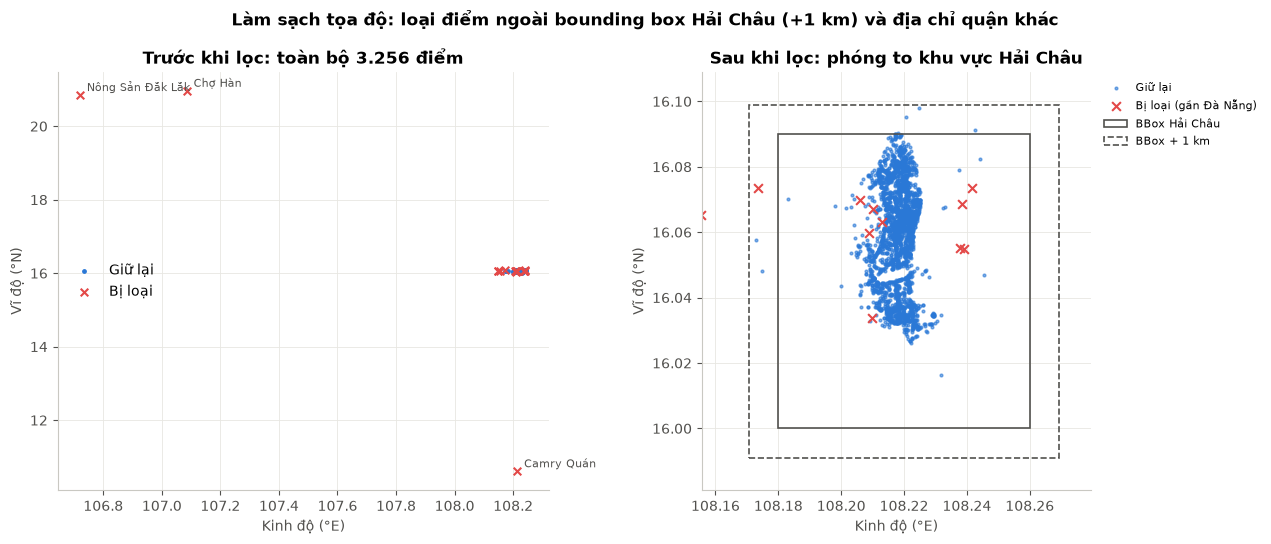

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))

ax = axes[0]
ax.scatter(df.loc[~drop_mask, "longitude"], df.loc[~drop_mask, "latitude"], s=6, c=viz.PALETTE[0], label="Giữ lại")
ax.scatter(df.loc[drop_mask, "longitude"], df.loc[drop_mask, "latitude"], s=30, c=viz.PALETTE[7], marker="x", label="Bị loại")
for _, r in df[df["is_coord_outlier"] & (~df["latitude"].between(15.5, 16.5))].iterrows():
    ax.annotate(r["storeName"], (r["longitude"], r["latitude"]), fontsize=8, xytext=(5, 3),
                textcoords="offset points", color=viz.TEXT_2)
ax.set_title("Trước khi lọc: toàn bộ 3.256 điểm")
ax.set_xlabel("Kinh độ (°E)"); ax.set_ylabel("Vĩ độ (°N)")
ax.legend(loc="center left")

ax = axes[1]
kept = df[~drop_mask]
ax.scatter(kept["longitude"], kept["latitude"], s=4, c=viz.PALETTE[0], alpha=0.6, label="Giữ lại")
near = df[drop_mask & df["latitude"].between(15.9, 16.2)]
ax.scatter(near["longitude"], near["latitude"], s=40, c=viz.PALETTE[7], marker="x", label="Bị loại (gần Đà Nẵng)")
for b, ls, lab in [(geo.HAI_CHAU_BBOX, "-", "BBox Hải Châu"), (bbox_buf, "--", "BBox + 1 km")]:
    ax.add_patch(patches.Rectangle((b["lon_min"], b["lat_min"]), b["lon_max"] - b["lon_min"],
                                   b["lat_max"] - b["lat_min"], fill=False, ls=ls, ec=viz.TEXT_2, lw=1.2, label=lab))
ax.set_xlim(bbox_buf["lon_min"] - 0.015, bbox_buf["lon_max"] + 0.01)
ax.set_ylim(bbox_buf["lat_min"] - 0.01, bbox_buf["lat_max"] + 0.01)
ax.set_aspect(1 / np.cos(np.radians(16.05)))
ax.set_title("Sau khi lọc: phóng to khu vực Hải Châu")
ax.set_xlabel("Kinh độ (°E)"); ax.set_ylabel("Vĩ độ (°N)")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=8)
fig.suptitle("Làm sạch tọa độ: loại điểm ngoài bounding box Hải Châu (+1 km) và địa chỉ quận khác", fontweight="bold")
fig.tight_layout()
viz.save_fig(fig, "01_coord_cleaning_before_after")
plt.show()

In [14]:
m = viz.base_map(zoom=13)
viz.add_points(m, df[~drop_mask], viz.PALETTE[0], "Giữ lại", radius=2)
viz.add_points(m, df[drop_mask], viz.PALETTE[7], "Bị loại", popup_cols=("storeName", "address", "latitude", "longitude"), radius=6)
for b, dash, lab in [(geo.HAI_CHAU_BBOX, None, "BBox Hải Châu"), (bbox_buf, "6", "BBox + 1 km")]:
    folium.Rectangle([[b["lat_min"], b["lon_min"]], [b["lat_max"], b["lon_max"]]], color="#52514e",
                     weight=2, fill=False, dash_array=dash, tooltip=lab).add_to(m)
folium.LayerControl().add_to(m)
map_path = viz.save_map(m, "01_coord_cleaning")
print("Đã lưu:", map_path.relative_to(ROOT))
viz.show_map(map_path)

Đã lưu: outputs\maps\01_coord_cleaning.html


In [15]:
n0 = len(df)
dropped = df[drop_mask].copy()
df = df[~drop_mask].copy()
log.add("5. Loại tọa độ ngoài bbox+1km & quận khác", n0, len(df), int(drop_mask.sum()),
        f"ngoài bbox: {int(dropped['is_coord_outlier'].sum())}; quận/tỉnh khác (trong bbox): "
        f"{int((dropped['is_district_inconsistent'] & ~dropped['is_coord_outlier']).sum())}")
print("Còn lại:", len(df))
print("\nward_final của các bản ghi còn lại:")
print(df["ward_final"].value_counts().to_string())

Còn lại: 3240

ward_final của các bản ghi còn lại:
ward_final
Hòa Cường Bắc     497
Hải Châu 1        342
Thạch Thang       329
Hòa Cường Nam     315
Phước Ninh        296
Hải Châu 2        203
Nam Dương         194
Hòa Thuận Tây     192
Thanh Bình        169
Bình Thuận        169
Thuận Phước       156
Hòa Thuận Đông    148
Bình Hiên         132
Ngoài Hải Châu     98


**Lưu ý:** sau khi lọc vẫn còn một số điểm có `ward_final = "Ngoài Hải Châu"`. Những điểm này nằm trong bbox nới rộng, sát ranh giới Thanh Khê / Cẩm Lệ / Sơn Trà, và địa chỉ không ghi phường Hải Châu.
Ta **giữ** chúng vì hai lý do. Thứ nhất, bbox chỉ là xấp xỉ. Thứ hai, chúng cung cấp ngữ cảnh mật độ cho phân cụm không gian. Khi phân tích theo phường, nhóm này được tách riêng.

## 6. `productType` đa nhãn

Khảo sát thực tế cho thấy có **51 nhãn gốc** chứ không phải khoảng 20. Nguyên nhân:
- **Nhãn huy hiệu Grab** không phải loại hình: "Tạp Dề Bạc", "Tạp Dề Vàng", "Deluxe by Grab", "Official Brand Store". Các nhãn này được tách ra cột `grab_badges` / `has_badge`.
- **Nhãn đồng nghĩa hoặc nhãn con**: "Noodles" và "Congee" là con của "Noodles & Congee", nên chuỗi "Noodles, Noodles & Congee" thực chất là trùng nghĩa. "Chè" gộp vào "Dessert", "Sushi" gộp vào "Japanese", ... (xem `cl.LABEL_MAP`).
- **Nhãn hiếm** (< 10 cửa hàng sau khi gộp) được gom vào "Others" (FOOD) hoặc "Other Store" (SHOP). Nhãn quá hiếm không đủ support cho luật kết hợp và chỉ làm tăng chiều cho mô hình.

In [16]:
df = cl.clean_product_types(df, min_count=10)
raw_labels = df["pt_raw"].explode().value_counts()
final_labels = df["product_types"].explode().value_counts()
print(f"Số nhãn gốc: {len(raw_labels)}  ->  số nhãn sau chuẩn hóa: {len(final_labels)}")
print(f"Số bản ghi có huy hiệu Grab: {df['has_badge'].sum()}")
print(f"Số tổ hợp productType: trước {df['productType'].nunique()} -> sau {df['product_types'].map(lambda L: tuple(sorted(L))).nunique()}")

mapping = (df[["pt_raw", "product_types"]].explode("pt_raw").dropna()
           .assign(mapped=lambda d: d["pt_raw"].map(lambda x: "(huy hiệu Grab)" if x in cl.BADGE_LABELS else cl.LABEL_MAP.get(x, x))))
label_map_tbl = (raw_labels.rename("n_raw").to_frame()
                 .join(mapping.drop_duplicates("pt_raw").set_index("pt_raw")["mapped"]))
label_map_tbl["final"] = label_map_tbl["mapped"].where(
    label_map_tbl["mapped"].isin(final_labels.index) | (label_map_tbl["mapped"] == "(huy hiệu Grab)"), "Others / Other Store (hiếm)")
label_map_tbl.to_csv(viz.TABLE_DIR / "01_product_type_label_map.csv", encoding="utf-8-sig")
label_map_tbl[label_map_tbl.index != label_map_tbl["final"]]

Số nhãn gốc: 51  ->  số nhãn sau chuẩn hóa: 20
Số bản ghi có huy hiệu Grab: 53
Số tổ hợp productType: trước 338 -> sau 167


,n_raw,mapped,final
pt_raw,,,
Noodles,145,Noodles & Congee,Noodles & Congee
Congee,33,Noodles & Congee,Noodles & Congee
Bánh Truyền Thống,27,Snack,Snack
Tạp Dề Bạc,26,(huy hiệu Grab),(huy hiệu Grab)
Chè,24,Dessert,Dessert
Tạp Dề Vàng,20,(huy hiệu Grab),(huy hiệu Grab)
Cake,15,Dessert,Dessert
Packaged food-dried food,14,Grocery,Grocery
Healthy - Salad,13,Healthy Food,Healthy Food


Các cột one-hot: ['pt_coffee_tea_juice', 'pt_noodles_congee', 'pt_rice', 'pt_snack', 'pt_hotpot_grill', 'pt_others', 'pt_milk_tea', 'pt_bread', 'pt_international_food', 'pt_dessert', 'pt_fast_food', 'pt_other_store', 'pt_healthy_food', 'pt_grocery', 'pt_pizza', 'pt_japanese', 'pt_seafood', 'pt_chicken', 'pt_beef', 'pt_korean']

Phân phối n_types:
n_types
1    2649
2     425
3     133
4      26
5       7


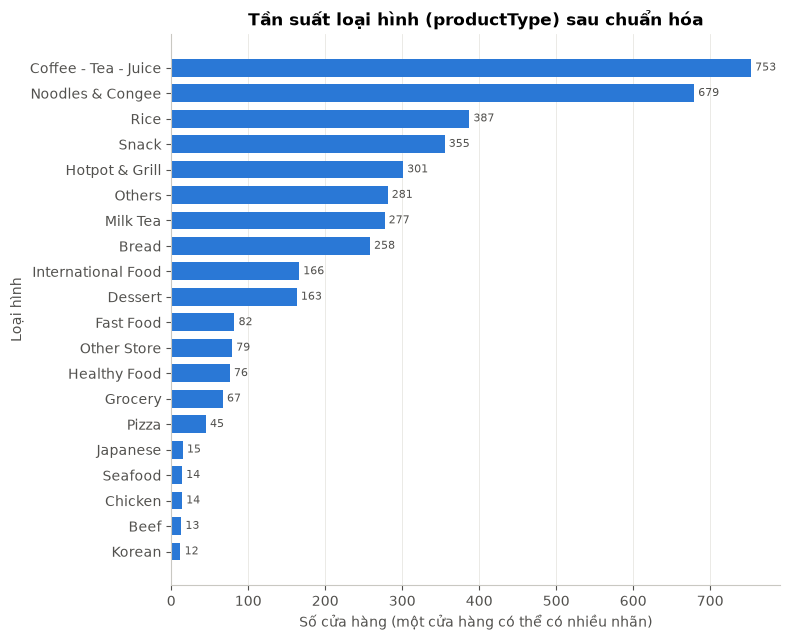

In [17]:
onehot = ft.multilabel_onehot(df["product_types"])
print("Các cột one-hot:", list(onehot.columns))
print("\nPhân phối n_types:")
print(df["n_types"].value_counts().sort_index().to_string())

fig, ax = plt.subplots(figsize=(8, 6.5))
viz.barh_counts(final_labels, "Tần suất loại hình (productType) sau chuẩn hóa",
                "Số cửa hàng (một cửa hàng có thể có nhiều nhãn)", "Loại hình", ax=ax)
fig.tight_layout(); viz.save_fig(fig, "01_product_type_freq"); plt.show()
log.add("6. Tách productType đa nhãn", len(df), len(df), int((df["pt_raw"].map(len) != df["n_types"]).sum()),
        f"{len(raw_labels)} nhãn gốc -> {len(final_labels)} nhãn; {int(df['has_badge'].sum())} bản ghi có huy hiệu Grab")

## 7. `flag` → `rating`

**Giả thuyết:** `flag = rating × 10` và `flag = 0` nghĩa là *chưa có đánh giá*. Ta kiểm chứng bằng phân phối:

In [18]:
vc = df["flag"].value_counts().sort_index()
print(vc.to_string())
nz = df.loc[df["flag"] > 0, "flag"]
print(f"\nflag=0: {(df['flag'] == 0).sum()} ({(df['flag'] == 0).mean():.1%}) | flag>0: min={nz.min()}, max={nz.max()}, "
      f"median={nz.median()}, mean={nz.mean():.2f}")
print("Mọi giá trị đều là số nguyên:", (df["flag"] % 1 == 0).all())
print("\nTỉ lệ flag=0 theo category:")
print(df.groupby("category")["flag"].apply(lambda s: (s == 0).mean()).map("{:.1%}".format).to_string())

flag
0     1568
30       5
36      24
37      31
38     388
39      44
40     415
41      39
42      68
43     114
44     199
45     345

flag=0: 1568 (48.4%) | flag>0: min=30, max=45, median=40.0, mean=41.18
Mọi giá trị đều là số nguyên: True

Tỉ lệ flag=0 theo category:
category
FOOD    46.1%
SHOP    77.4%


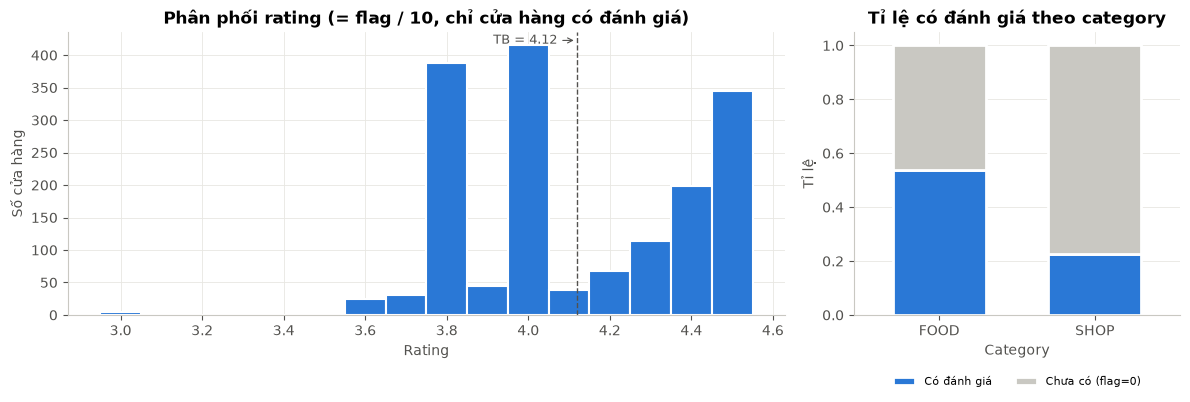

In [19]:
df = cl.add_rating(df)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw={"width_ratios": [2.2, 1]})
ax = axes[0]
r = df["rating"].dropna()
bins = np.arange(r.min() - 0.05, r.max() + 0.1, 0.1)
ax.hist(r, bins=bins, color=viz.PALETTE[0], edgecolor="white", linewidth=1.5)
ax.axvline(r.mean(), color=viz.TEXT_2, ls="--", lw=1)
ax.annotate(f"TB = {r.mean():.2f}", (r.mean(), ax.get_ylim()[1] * 0.97), xytext=(-60, 0), textcoords="offset points",
            color=viz.TEXT_2, fontsize=9, va="center", arrowprops=dict(arrowstyle="->", color=viz.TEXT_2, lw=0.8))
ax.set_title("Phân phối rating (= flag / 10, chỉ cửa hàng có đánh giá)")
ax.set_xlabel("Rating"); ax.set_ylabel("Số cửa hàng")
ax = axes[1]
share = df.groupby("category")["has_rating"].value_counts(normalize=True).unstack().reindex(columns=[True, False])
share.columns = ["Có đánh giá", "Chưa có (flag=0)"]
share.plot(kind="bar", stacked=True, ax=ax, color=[viz.PALETTE[0], "#c9c8c2"], width=0.6, edgecolor="white", linewidth=2)
ax.set_title("Tỉ lệ có đánh giá theo category")
ax.set_xlabel("Category"); ax.set_ylabel("Tỉ lệ"); ax.tick_params(axis="x", rotation=0)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=2, fontsize=8)
fig.tight_layout(); viz.save_fig(fig, "01_rating_distribution"); plt.show()
log.add("7. flag -> rating, has_rating (giả định)", len(df), len(df), int((~df["has_rating"]).sum()),
        "rating = flag/10; flag=0 -> NaN (chưa có đánh giá)")

**Đánh giá giả thuyết:**
- Ủng hộ: các giá trị khác 0 là số nguyên trong đoạn 30–45, tức rating 3.0–4.5 với bước 0.1. Đây đúng là định dạng sao của Grab (1 chữ số thập phân). Phân phối lệch về phía cao, mode khoảng 4.0, đúng kiểu rating trên nền tảng giao đồ ăn.
  `flag = 0` chiếm gần một nửa và tập trung ở SHOP, là nhóm ít được đánh giá. Điều này hợp lý với nghĩa "chưa có đánh giá".
- Điểm bất thường: **không có giá trị nào trên 45 (4.5 sao)** và không có giá trị dưới 30. Rating thật trên Grab có thể đạt 4.6–5.0. Có thể dữ liệu đã bị cắt (clip), hoặc `flag` là một chỉ số khác có thang tương tự.
- **Kết luận: đây là GIẢ ĐỊNH, sẽ được nêu rõ trong phần Hạn chế của báo cáo.** Mọi phân tích về rating ở notebook 05 chỉ dùng `has_rating = True`.

## 8. Khử trùng listing

Một số cửa hàng được đăng **hai lần** trên Grab: cùng tên, cùng tọa độ, cùng địa chỉ, nhưng khác `storeId` (vd một listing có huy hiệu "Tạp Dề", một listing không).
Nếu giữ nguyên, mật độ không gian và luật co-location sẽ bị thổi phồng.

**Khóa trùng:** tên (bỏ dấu) + tọa độ làm tròn 5 chữ số (~1 m) + phần đầu địa chỉ (số nhà + đường).
Các sạp trong cùng một chợ (vd Chợ Cồn) có **cùng tọa độ nhưng khác số lô**, nên vẫn được giữ là các cửa hàng riêng.
Khi gộp: hợp nhất danh sách loại hình; rating lấy trung bình các listing có đánh giá.

In [20]:
n0 = len(df)
df, dup_groups = cl.deduplicate(df)
print(f"Số listing thuộc nhóm trùng: {len(dup_groups)} | trước: {n0} -> sau: {len(df)} (gộp {n0 - len(df)})")
print(f"Số cặp trùng tọa độ còn lại (khác cửa hàng, vd sạp chợ / trung tâm thương mại): "
      f"{df.duplicated(['latitude', 'longitude']).sum()}")
dup_groups[["storeName", "address", "flag", "productType", "storeId"]].head(12)

Số listing thuộc nhóm trùng: 64 | trước: 3240 -> sau: 3208 (gộp 32)
Số cặp trùng tọa độ còn lại (khác cửa hàng, vd sạp chợ / trung tâm thương mại): 123


,storeName,address,flag,productType,storeId
2881,Bánh Mì Khói,"23 Ngô Gia Tự, Phường Hải Châu 1, Quận Hải Châu",0,Bread,FOOD94537585
2236,Bánh Mì Khói,"23 Ngô Gia Tự, Phường Hải Châu 1, Quận Hải Châu",0,"Bread, Tạp Dề Bạc",FOOD27954565
2884,Bee Milktea & Coffee,"93 Nguyễn Hữu Thọ, Phường Hòa Thuận Tây, Quận Hải Châu",0,Milk Tea,FOOD35232274
445,Bee Milktea & Coffee,"93 Nguyễn Hữu Thọ, Phường Hòa Thuận Tây, Quận Hải Châu",0,"Milk Tea, Tạp Dề Bạc",FOOD54617663
2584,Bento Delichi,"53 Hưng Hóa 1, Phường Hòa Cường Nam, Quận Hải Châu",38,"Rice, Tạp Dề Vàng",FOOD33759268
1284,Bento Delichi,"53 Hưng Hóa 1, Phường Hòa Cường Nam, Quận Hải Châu",0,Rice,FOOD38119992
2614,Bento Delichi,"46 Đầm Rong 2, phường Thanh Bình, Quận Hải Châu",0,"Rice, Tạp Dề Vàng",FOOD65951006
2356,Bento Delichi,"46 Đầm Rong 2, phường Thanh Bình, Quận Hải Châu",0,Rice,FOOD34521879
3164,Bros Kitchen BBQ & Beer,"60 Nguyễn Chí Thanh, Phường Hải Châu 1",45,Hotpot & Grill,FOOD43531552
228,Bros Kitchen BBQ & Beer,"60 Nguyễn Chí Thanh, Phường Hải Châu 1",45,Hotpot & Grill,FOOD84227457


In [21]:
log.add("8. Khử trùng listing", n0, len(df), n0 - len(df),
        f"{len(dup_groups)} listing thuộc nhóm trùng; gộp product_types, rating TB")

## 9. Phát hiện chuỗi cửa hàng (chain)

`brand` = tên → bỏ dấu → lowercase → cắt phần sau `" - "` hoặc `"("`. Phần sau thường là tên đường hoặc chi nhánh, vd "Cơm Bếp Ngọ- Lê Duẩn" → "com bep ngo".
Hai quy tắc bảo vệ:
- Chỉ cắt khi phần đầu còn **≥ 2 từ**, để tránh brand chung chung kiểu "banh mi" gom nhầm các quán độc lập.
- Gạch nối **không có khoảng trắng** ("Tea-Rex", "Family1-Shop") là một phần của tên nên được giữ nguyên.

`is_chain = True` nếu `brand` xuất hiện ≥ 2 lần (sau khi khử trùng listing, nên đây là ≥ 2 **địa điểm**), **trừ hai trường hợp**:
- **Tên chung chung** (`cl.GENERIC_BRANDS`, vd "bún bò", "trà sữa", "ăn vặt", "phở", "bánh mì"): đây là nhiều quán độc lập trùng tên món chứ không phải một chuỗi. Danh sách được lập thủ công sau khi rà toàn bộ brand có ≥ 2 địa điểm.
- **Sạp trong chợ** (`cl.MARKET_BRANDS`: "Chợ Cồn", "Chợ Hàn"): các sạp đặt tên theo chợ.

In [22]:
df = cl.add_chain(df, min_count=2)
ex = df.loc[df["storeName"].str.contains(r" - |\(|– |- | -", regex=True), ["storeName", "brand"]].head(10)
print("Ví dụ chuẩn hóa tên -> brand:")
print(ex.to_string(index=False))
print(f"\nSố brand: {df['brand'].nunique()} | số brand là chain: {df.loc[df['is_chain'], 'brand'].nunique()} "
      f"| số cửa hàng thuộc chain: {df['is_chain'].sum()} ({df['is_chain'].mean():.1%})")
print(f"Bị loại khỏi chain vì tên chung chung: {(df['is_generic_name'] & (df['brand_count'] >= 2)).sum()} cửa hàng | "
      f"sạp chợ: {df['is_market_stall'].sum()}")
top_brands = df.loc[df["is_chain"], "brand"].value_counts().head(15)
top_brands

Ví dụ chuẩn hóa tên -> brand:
                                    storeName                       brand
                     Cháo Lòng 47- Hàn Thuyên                chao long 47
             Tiệm Ăn PY Fud -Nguyễn Chí Thanh              tiem an py fud
Nhím Food Bánh Ướt Lòng Gà- Bánh Hỏi Heo quay  nhim food banh uot long ga
                             Bò Né- Bò Kho 91                       bo ne
                       Bánh Mì -Gò Chả Chị Ba                     banh mi
             Cafe & Trà sữa BandB- Lê Đình Lý        cafe & tra sua bandb
        Mộc Tea- Trà Dâu & Nước Mía Sầu Riêng                     moc tea
 Tiệm Bánh Nhà Làm Tiên Tiên- Lê Thị Hồng Gấm tiem banh nha lam tien tien
     Bánh mỳ Kebab Sunrise- 200 Lê Thanh Nghị       banh my kebab sunrise
   Cao Lầu Xôi Mỳ Xíu Nhà 39- Nguyễn Văn Linh   cao lau xoi my xiu nha 39

Số brand: 2711 | số brand là chain: 274 | số cửa hàng thuộc chain: 705 (22.0%)
Bị loại khỏi chain vì tên chung chung: 83 cửa hàng | sạp chợ: 20


brand
highlands coffee                28
dong tien bakery                10
royaltea                         8
the coffee house                 8
tiem an cho lon                  6
kebab torki                      6
nutifood ngoi nha dinh duong     6
trung nguyen legend              5
bo ne 3 ngon                     5
milano coffee                    5
bonpas bakery & coffee           5
mi quang ba mua                  5
heineken vn official store       5
milano coffee premium            5
the cups coffee                  5
Name: count, dtype: int64

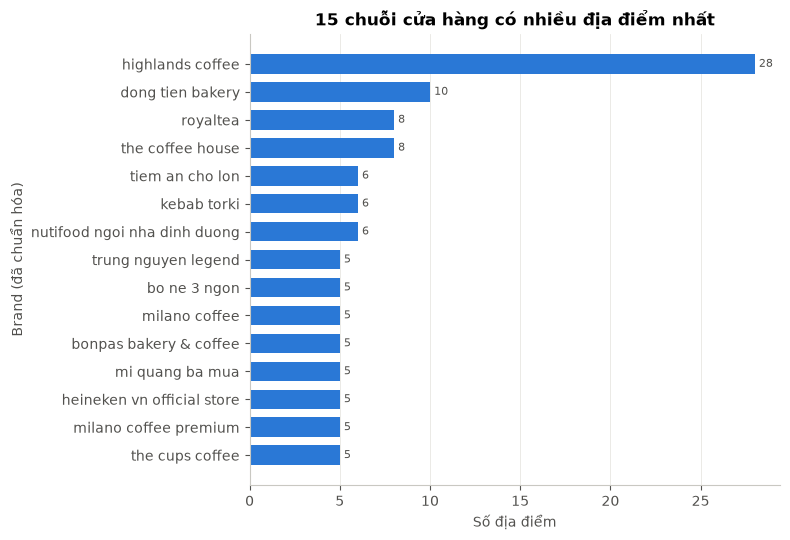

In [23]:
fig, ax = plt.subplots(figsize=(8, 5.5))
viz.barh_counts(top_brands, "15 chuỗi cửa hàng có nhiều địa điểm nhất", "Số địa điểm", "Brand (đã chuẩn hóa)", ax=ax)
fig.tight_layout(); viz.save_fig(fig, "01_top_chains"); plt.show()
log.add("9. Phát hiện chain (brand, is_chain)", len(df), len(df), int(df["is_chain"].sum()),
        f"{df.loc[df['is_chain'], 'brand'].nunique()} brand có ≥2 địa điểm")

**Lưu ý:** việc phát hiện chain dựa trên tên nên vẫn còn nhiễu. Có thể bỏ sót chuỗi viết tên khác nhau (vd "Milano Coffee" và "Milano Coffee Premium" đang là hai brand), hoặc gộp nhầm các quán trùng tên ngắn. Cột `brand_count` được giữ để mô hình có thể dùng thay cho cờ nhị phân.

## 10. Xuất dữ liệu sạch và bảng log

In [24]:
onehot = ft.multilabel_onehot(df["product_types"])
keep_cols = ["storeId", "storeName", "brand", "brand_count", "is_chain", "is_generic_name", "is_market_stall", "category",
             "address", "district", "ward_final", "ward_name", "ward_district", "ward_addr", "is_ward_conflict",
             "latitude", "longitude", "flag", "rating", "has_rating",
             "productType", "n_types", "has_badge", "n_listings", "merged_ids"]
out = df[keep_cols].copy()
out["product_types"] = df["product_types"].map("|".join)
out["grab_badges"] = df["grab_badges"].map("|".join)
out = pd.concat([out.reset_index(drop=True), onehot.reset_index(drop=True)], axis=1)
out.to_csv(OUT_PATH, index=False, encoding="utf-8-sig")
print("Đã ghi:", OUT_PATH.relative_to(ROOT), out.shape)

log_df = log.to_frame()
log_df.to_csv(viz.TABLE_DIR / "01_cleaning_log.csv", index=False, encoding="utf-8-sig")
dropped[["storeId", "storeName", "address", "district_raw", "latitude", "longitude",
         "is_coord_outlier", "is_district_inconsistent"]].to_csv(viz.TABLE_DIR / "01_dropped_records.csv",
                                                                index=False, encoding="utf-8-sig")
log_df

Đã ghi: data\processed\stores_clean.csv (3208, 47)


,step,n_before,n_after,n_affected,note
0,"2. Chuẩn hóa chuỗi (NFC, strip, khoảng trắng)",3256,3256,118,storeName=34; district=14; address=93
1,3. Chuẩn hóa district,3256,3256,2238,20 biến thể -> 1 giá trị chuẩn; 12 bản ghi bị đánh cờ ngoài Hải Châu
2,"4. Tách phường (ward_name, ward_addr, ward_final)",3256,3256,1341,tỉ lệ khớp 2 nguồn 48.5%; ưu tiên phường trong address
3,5. Loại tọa độ ngoài bbox+1km & quận khác,3256,3240,16,ngoài bbox: 6; quận/tỉnh khác (trong bbox): 10
4,6. Tách productType đa nhãn,3240,3240,212,51 nhãn gốc -> 20 nhãn; 53 bản ghi có huy hiệu Grab
5,"7. flag -> rating, has_rating (giả định)",3240,3240,1568,rating = flag/10; flag=0 -> NaN (chưa có đánh giá)
6,8. Khử trùng listing,3240,3208,32,"64 listing thuộc nhóm trùng; gộp product_types, rating TB"
7,"9. Phát hiện chain (brand, is_chain)",3208,3208,705,274 brand có ≥2 địa điểm


In [25]:
# Kiểm tra lại file đã xuất
chk = pd.read_csv(OUT_PATH)
assert chk["storeId"].is_unique
assert chk["latitude"].between(bbox_buf["lat_min"], bbox_buf["lat_max"]).all()
assert (chk["district"] == cl.DISTRICT_CANONICAL).all()
assert chk.loc[chk["has_rating"], "rating"].notna().all() and chk.loc[~chk["has_rating"], "rating"].isna().all()
print("OK –", chk.shape, "| category:", chk["category"].value_counts().to_dict(),
      "| has_rating:", int(chk["has_rating"].sum()))
print("ward_final:", chk["ward_final"].value_counts().to_dict())

OK – (3208, 47) | category: {'FOOD': 2976, 'SHOP': 232} | has_rating: 1661
ward_final: {'Hòa Cường Bắc': 492, 'Hải Châu 1': 336, 'Thạch Thang': 327, 'Hòa Cường Nam': 312, 'Phước Ninh': 293, 'Hải Châu 2': 202, 'Nam Dương': 193, 'Hòa Thuận Tây': 189, 'Thanh Bình': 167, 'Bình Thuận': 167, 'Thuận Phước': 154, 'Hòa Thuận Đông': 147, 'Bình Hiên': 131, 'Ngoài Hải Châu': 98}


## Tóm tắt notebook 01

| Hạng mục | Kết quả |
|---|---|
| Số bản ghi | 3.256 → **3.208** (loại 16 bản ghi sai vị trí, gộp 32 listing trùng) |
| Tọa độ | 6 điểm ngoài bbox+1km (TP.HCM, Hải Phòng/Quảng Ninh, Liên Chiểu); 8 điểm được giữ nhờ biên 1 km |
| district | 20 biến thể → 1 giá trị; 12 bản ghi địa chỉ thuộc quận/tỉnh khác (gồm 2 cửa hàng ở Hải An – **Hải Phòng**) |
| Phường | trường `ward` và phường trong `address` chỉ khớp **48,5%**; `ward` thiếu hẳn Phước Ninh, Bình Hiên → ưu tiên `address` |
| productType | 51 nhãn gốc → **20 nhãn** (tách 4 nhãn huy hiệu Grab, gộp đồng nghĩa, gom nhãn hiếm) |
| Rating | 1.661 cửa hàng (51,8%) có đánh giá, rating 3.0–4.5; `flag = rating×10` là **giả định** |
| Chain | 274 brand có ≥ 2 địa điểm, 705 cửa hàng (22,0%) |

**Đầu ra:** `data/processed/stores_clean.csv`, `outputs/tables/01_cleaning_log.csv`, `01_dropped_records.csv`, `01_product_type_label_map.csv`,
`outputs/figures/01_*.png`, `outputs/maps/01_coord_cleaning.html`.